**PUSL 3123-Assesment 01**


**Excersice 04**

In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt

# Check device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch Version:", torch.__version__)
print("Device:", device)
print("GPU Available:", torch.cuda.is_available())


PyTorch Version: 2.14.1+cu130
Device: cuda
GPU Available: True


In [ ]:

import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split

# Same normalization values as Exercise 1
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

# Download training dataset
full_train_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

# Load test dataset
test_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

# Same dataset splitting method as Exercise 1
generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [40000, 10000],
    generator=generator
)

# Create DataLoaders
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))


Training images: 40000
Validation images: 10000
Testing images: 10000


**Create CNN Models**

In [ ]:

class CNN(nn.Module):
    def __init__(self, filters1, filters2):
        super(CNN, self).__init__()

        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, filters1, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(filters1, filters2, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(filters2 * 8 * 8, 10)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x


# Create three CNN models
small_cnn = CNN(16, 32).to(device)
medium_cnn = CNN(32, 64).to(device)
large_cnn = CNN(64, 128).to(device)


# Count trainable parameters
def count_parameters(model):
    return sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )


print("Small CNN Parameters:", count_parameters(small_cnn))
print("Medium CNN Parameters:", count_parameters(medium_cnn))
print("Large CNN Parameters:", count_parameters(large_cnn))


Small CNN Parameters: 25578
Medium CNN Parameters: 60362
Large CNN Parameters: 157578


**Train CNN Models**

In [ ]:

# Training settings
epochs = 10
learning_rate = 0.001

# Training function
def train_model(model, train_loader, val_loader):

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    train_losses = []
    val_accuracies = []

    for epoch in range(epochs):

        model.train()
        running_loss = 0.0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        epoch_loss = running_loss / len(train_loader)
        train_losses.append(epoch_loss)

        # Validation
        model.eval()
        correct = 0
        total = 0

        with torch.no_grad():
            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                _, predicted = torch.max(outputs, 1)

                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        accuracy = 100 * correct / total
        val_accuracies.append(accuracy)

        print(
            f"Epoch [{epoch+1}/{epochs}], "
            f"Loss: {epoch_loss:.4f}, "
            f"Validation Accuracy: {accuracy:.2f}%"
        )

    return train_losses, val_accuracies


**Train Small CNN**

In [ ]:

print("Training Small CNN")
small_loss, small_acc = train_model(
    small_cnn, train_loader, val_loader
)

Training Small CNN
Epoch [1/10], Loss: 1.4603, Validation Accuracy: 57.21%
Epoch [2/10], Loss: 1.1288, Validation Accuracy: 62.86%
Epoch [3/10], Loss: 0.9970, Validation Accuracy: 64.87%
Epoch [4/10], Loss: 0.9202, Validation Accuracy: 65.66%
Epoch [5/10], Loss: 0.8651, Validation Accuracy: 66.17%
Epoch [6/10], Loss: 0.8268, Validation Accuracy: 66.65%
Epoch [7/10], Loss: 0.7935, Validation Accuracy: 67.28%
Epoch [8/10], Loss: 0.7644, Validation Accuracy: 67.85%
Epoch [9/10], Loss: 0.7400, Validation Accuracy: 67.60%
Epoch [10/10], Loss: 0.7136, Validation Accuracy: 67.98%


**Train Medium CNN**

In [ ]:

print("\nTraining Medium CNN")
medium_loss, medium_acc = train_model(
    medium_cnn, train_loader, val_loader
)


Training Medium CNN
Epoch [1/10], Loss: 1.3645, Validation Accuracy: 61.05%
Epoch [2/10], Loss: 1.0105, Validation Accuracy: 65.58%
Epoch [3/10], Loss: 0.8864, Validation Accuracy: 66.61%
Epoch [4/10], Loss: 0.7980, Validation Accuracy: 68.75%
Epoch [5/10], Loss: 0.7343, Validation Accuracy: 68.20%
Epoch [6/10], Loss: 0.6735, Validation Accuracy: 69.73%
Epoch [7/10], Loss: 0.6261, Validation Accuracy: 69.61%
Epoch [8/10], Loss: 0.5796, Validation Accuracy: 69.36%
Epoch [9/10], Loss: 0.5428, Validation Accuracy: 70.37%
Epoch [10/10], Loss: 0.5076, Validation Accuracy: 69.68%


**Train Large CNN**

In [ ]:

print("\nTraining Large CNN")
large_loss, large_acc = train_model(
    large_cnn, train_loader, val_loader
)



Training Large CNN
Epoch [1/10], Loss: 1.3461, Validation Accuracy: 63.13%
Epoch [2/10], Loss: 0.9799, Validation Accuracy: 66.68%
Epoch [3/10], Loss: 0.8508, Validation Accuracy: 67.64%
Epoch [4/10], Loss: 0.7736, Validation Accuracy: 69.68%
Epoch [5/10], Loss: 0.7057, Validation Accuracy: 69.62%
Epoch [6/10], Loss: 0.6476, Validation Accuracy: 70.18%
Epoch [7/10], Loss: 0.6002, Validation Accuracy: 70.07%
Epoch [8/10], Loss: 0.5622, Validation Accuracy: 70.54%
Epoch [9/10], Loss: 0.5226, Validation Accuracy: 70.06%
Epoch [10/10], Loss: 0.4919, Validation Accuracy: 70.02%


**Width Comparison Graphs**

**Validation Accuracy Comparison**

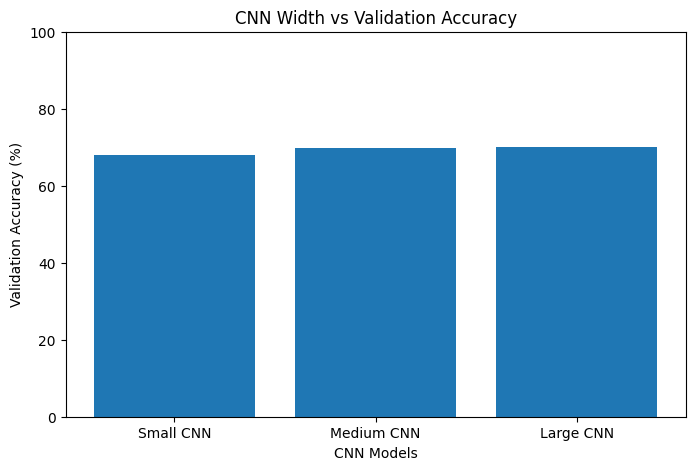

In [ ]:
models = ['Small CNN', 'Medium CNN', 'Large CNN']

accuracies = [
    small_acc[-1],
    medium_acc[-1],
    large_acc[-1]
]

plt.figure(figsize=(8,5))

plt.bar(models, accuracies)

plt.title('CNN Width vs Validation Accuracy')
plt.xlabel('CNN Models')
plt.ylabel('Validation Accuracy (%)')

plt.ylim(0, 100)
plt.show()

**Training Loss Comparison**

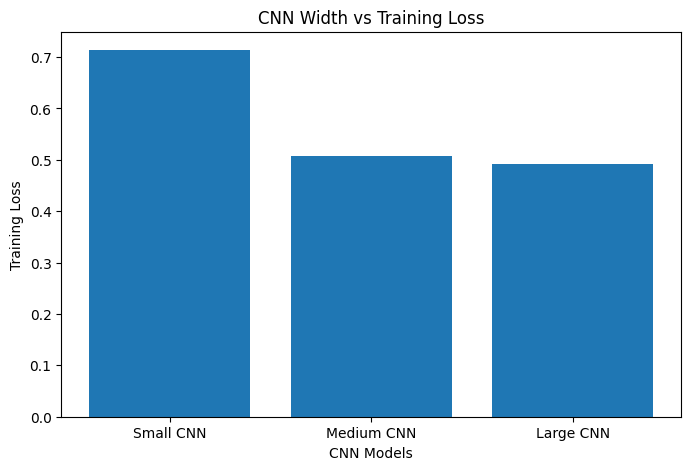

In [ ]:

models = ['Small CNN', 'Medium CNN', 'Large CNN']

losses = [
    small_loss[-1],
    medium_loss[-1],
    large_loss[-1]
]

plt.figure(figsize=(8,5))
plt.bar(models, losses)

plt.title('CNN Width vs Training Loss')
plt.xlabel('CNN Models')
plt.ylabel('Training Loss')

plt.show()


**Training Performance Graph**

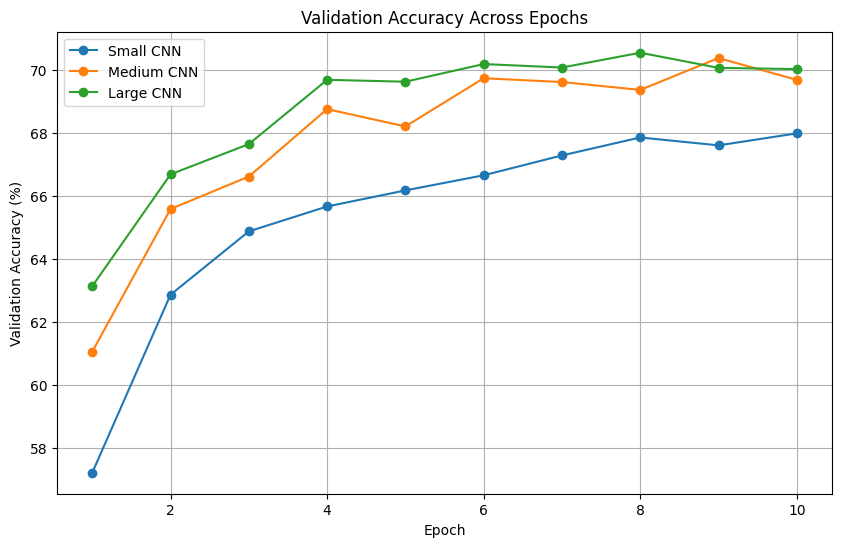

In [ ]:
plt.figure(figsize=(10,6))

plt.plot(range(1, 11), small_acc, marker='o', label='Small CNN')
plt.plot(range(1, 11), medium_acc, marker='o', label='Medium CNN')
plt.plot(range(1, 11), large_acc, marker='o', label='Large CNN')

plt.title('Validation Accuracy Across Epochs')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy (%)')

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
print("Small CNN Loss:", small_loss[-1])
print("Medium CNN Loss:", medium_loss[-1])
print("Large CNN Loss:", large_loss[-1])

Small CNN Loss: 0.7136117439746856
Medium CNN Loss: 0.5076373426914215
Large CNN Loss: 0.49191763455867765


In [ ]:
print("Small CNN Accuracy:", small_acc[-1])
print("Medium CNN Accuracy:", medium_acc[-1])
print("Large CNN Accuracy:", large_acc[-1])

Small CNN Accuracy: 67.98
Medium CNN Accuracy: 69.68
Large CNN Accuracy: 70.02


In [ ]:

import pandas as pd

results = {
    'Model': ['Small CNN', 'Medium CNN', 'Large CNN'],
    'Parameters': [
        count_parameters(small_cnn),
        count_parameters(medium_cnn),
        count_parameters(large_cnn)
    ],
    'Training Loss': [
        small_loss[-1],
        medium_loss[-1],
        large_loss[-1]
    ],
    'Validation Accuracy': [
        small_acc[-1],
        medium_acc[-1],
        large_acc[-1]
    ]
}

df = pd.DataFrame(results)
print(df.to_string(index=False))


     Model  Parameters  Training Loss  Validation Accuracy
 Small CNN       25578       0.713612                67.98
Medium CNN       60362       0.507637                69.68
 Large CNN      157578       0.491918                70.02


**Discussion**

### Width Experiment – Discussion

The width experiment evaluated the effect of increasing the number of filters in CNN architectures. Three models were tested: Small CNN, Medium CNN, and Large CNN.

The Small CNN achieved a validation accuracy of 67.98%, while the Medium CNN achieved 69.68%. The Large CNN obtained the highest validation accuracy of 70.02%.

The number of trainable parameters increased from 25,578 in the Small CNN to 157,578 in the Large CNN. Training loss also decreased from 0.713612 to 0.491918.

These results indicate that increasing model width improved validation performance in this experiment. However, the improvement between the Medium and Large CNN was relatively small compared with the increase in model complexity.

**Depth CNN Architecture**

In [ ]:

class DepthCNN(nn.Module):

    def __init__(self, num_layers):
        super(DepthCNN, self).__init__()

        layers = []

        # First convolutional layer
        layers.append(
            nn.Conv2d(3, 32, kernel_size=3, padding=1)
        )
        layers.append(nn.ReLU())

        # Additional convolutional layers
        for _ in range(num_layers - 1):
            layers.append(
                nn.Conv2d(32, 32, kernel_size=3, padding=1)
            )
            layers.append(nn.ReLU())

        self.conv_layers = nn.Sequential(*layers)

        self.fc_layers = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(32, 10)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x


# Create depth models
shallow_cnn = DepthCNN(2).to(device)
medium_depth_cnn = DepthCNN(3).to(device)
deep_cnn = DepthCNN(4).to(device)


# Count parameters
print("Shallow CNN Parameters:",
      count_parameters(shallow_cnn))

print("Medium-depth CNN Parameters:",
      count_parameters(medium_depth_cnn))

print("Deep CNN Parameters:",
      count_parameters(deep_cnn))


Shallow CNN Parameters: 10474
Medium-depth CNN Parameters: 19722
Deep CNN Parameters: 28970


**Train Depth Models**


**Training Shallow CNN**

In [ ]:
print("Training Shallow CNN")

shallow_loss, shallow_acc = train_model(
    shallow_cnn,
    train_loader,
    val_loader
)

Training Shallow CNN
Epoch [1/10], Loss: 1.7210, Validation Accuracy: 36.14%
Epoch [2/10], Loss: 1.6796, Validation Accuracy: 38.15%
Epoch [3/10], Loss: 1.6463, Validation Accuracy: 38.13%
Epoch [4/10], Loss: 1.6161, Validation Accuracy: 41.10%
Epoch [5/10], Loss: 1.5830, Validation Accuracy: 43.23%
Epoch [6/10], Loss: 1.5520, Validation Accuracy: 44.88%
Epoch [7/10], Loss: 1.5211, Validation Accuracy: 46.37%
Epoch [8/10], Loss: 1.4911, Validation Accuracy: 47.27%
Epoch [9/10], Loss: 1.4663, Validation Accuracy: 48.11%
Epoch [10/10], Loss: 1.4438, Validation Accuracy: 48.13%


**Training Medium-depth CNN**

In [ ]:
print("\nTraining Medium-depth CNN")

medium_depth_loss, medium_depth_acc = train_model(
    medium_depth_cnn,
    train_loader,
    val_loader
)


Training Medium-depth CNN
Epoch [1/10], Loss: 1.8928, Validation Accuracy: 34.63%
Epoch [2/10], Loss: 1.6793, Validation Accuracy: 38.12%
Epoch [3/10], Loss: 1.6078, Validation Accuracy: 40.09%
Epoch [4/10], Loss: 1.5517, Validation Accuracy: 44.87%
Epoch [5/10], Loss: 1.5054, Validation Accuracy: 46.92%
Epoch [6/10], Loss: 1.4667, Validation Accuracy: 49.15%
Epoch [7/10], Loss: 1.4308, Validation Accuracy: 49.70%
Epoch [8/10], Loss: 1.3978, Validation Accuracy: 49.96%
Epoch [9/10], Loss: 1.3666, Validation Accuracy: 52.04%
Epoch [10/10], Loss: 1.3432, Validation Accuracy: 51.75%



**Training Deep CNN**

In [ ]:
print("\nTraining Deep CNN")

deep_loss, deep_acc = train_model(
    deep_cnn,
    train_loader,
    val_loader
)


Training Deep CNN
Epoch [1/10], Loss: 1.8802, Validation Accuracy: 34.83%
Epoch [2/10], Loss: 1.6576, Validation Accuracy: 39.17%
Epoch [3/10], Loss: 1.5664, Validation Accuracy: 44.11%
Epoch [4/10], Loss: 1.4910, Validation Accuracy: 47.05%
Epoch [5/10], Loss: 1.4314, Validation Accuracy: 50.33%
Epoch [6/10], Loss: 1.3723, Validation Accuracy: 51.30%
Epoch [7/10], Loss: 1.3348, Validation Accuracy: 53.04%
Epoch [8/10], Loss: 1.2905, Validation Accuracy: 53.33%
Epoch [9/10], Loss: 1.2564, Validation Accuracy: 54.54%
Epoch [10/10], Loss: 1.2343, Validation Accuracy: 57.31%


**DEPTH RESULTS TABLE**

In [ ]:

depth_results = {
    'Model': [
        'Shallow CNN',
        'Medium-depth CNN',
        'Deep CNN'
    ],

    'Parameters': [
        count_parameters(shallow_cnn),
        count_parameters(medium_depth_cnn),
        count_parameters(deep_cnn)
    ],

    'Training Loss': [
        shallow_loss[-1],
        medium_depth_loss[-1],
        deep_loss[-1]
    ],

    'Validation Accuracy': [
        shallow_acc[-1],
        medium_depth_acc[-1],
        deep_acc[-1]
    ]
}

depth_df = pd.DataFrame(depth_results)

print(depth_df.to_string(index=False))


           Model  Parameters  Training Loss  Validation Accuracy
     Shallow CNN       10474       1.443772                48.13
Medium-depth CNN       19722       1.343183                51.75
        Deep CNN       28970       1.234279                57.31


**Validation Accuracy Graph**

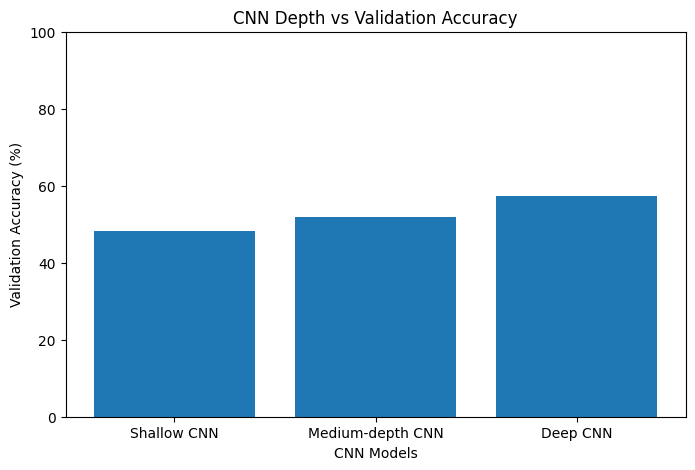

In [ ]:

depth_models = [
    'Shallow CNN',
    'Medium-depth CNN',
    'Deep CNN'
]

depth_accuracies = [
    shallow_acc[-1],
    medium_depth_acc[-1],
    deep_acc[-1]
]

plt.figure(figsize=(8, 5))

plt.bar(depth_models, depth_accuracies)

plt.title('CNN Depth vs Validation Accuracy')
plt.xlabel('CNN Models')
plt.ylabel('Validation Accuracy (%)')

plt.ylim(0, 100)
plt.show()


**Training Loss Graph**

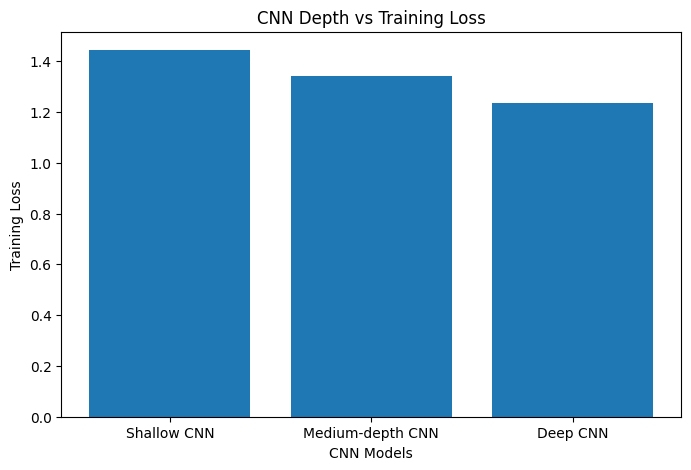

In [ ]:

depth_losses = [
    shallow_loss[-1],
    medium_depth_loss[-1],
    deep_loss[-1]
]

plt.figure(figsize=(8, 5))

plt.bar(depth_models, depth_losses)

plt.title('CNN Depth vs Training Loss')
plt.xlabel('CNN Models')
plt.ylabel('Training Loss')

plt.show()


**Validation Accuracy Across Epochs**

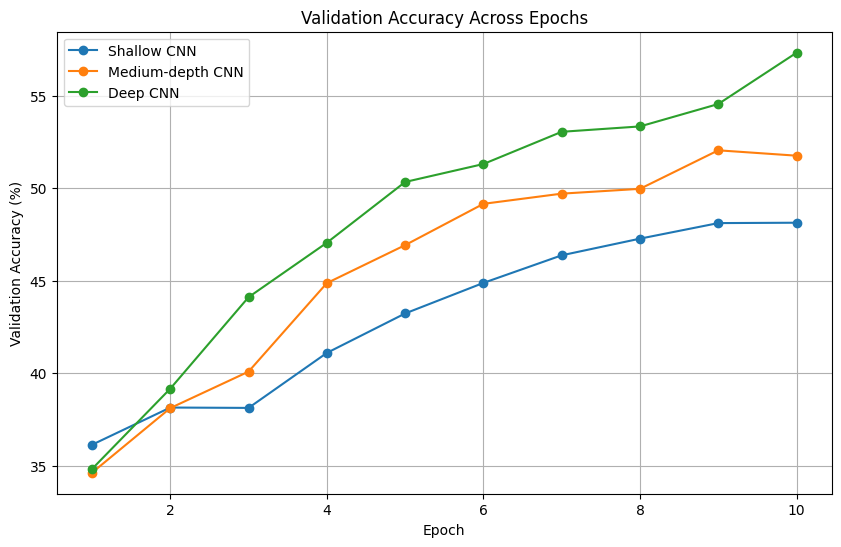

In [ ]:

plt.figure(figsize=(10, 6))

plt.plot(range(1, 11), shallow_acc,
         marker='o', label='Shallow CNN')

plt.plot(range(1, 11), medium_depth_acc,
         marker='o', label='Medium-depth CNN')

plt.plot(range(1, 11), deep_acc,
         marker='o', label='Deep CNN')

plt.title('Validation Accuracy Across Epochs')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy (%)')

plt.legend()
plt.grid(True)

plt.show()


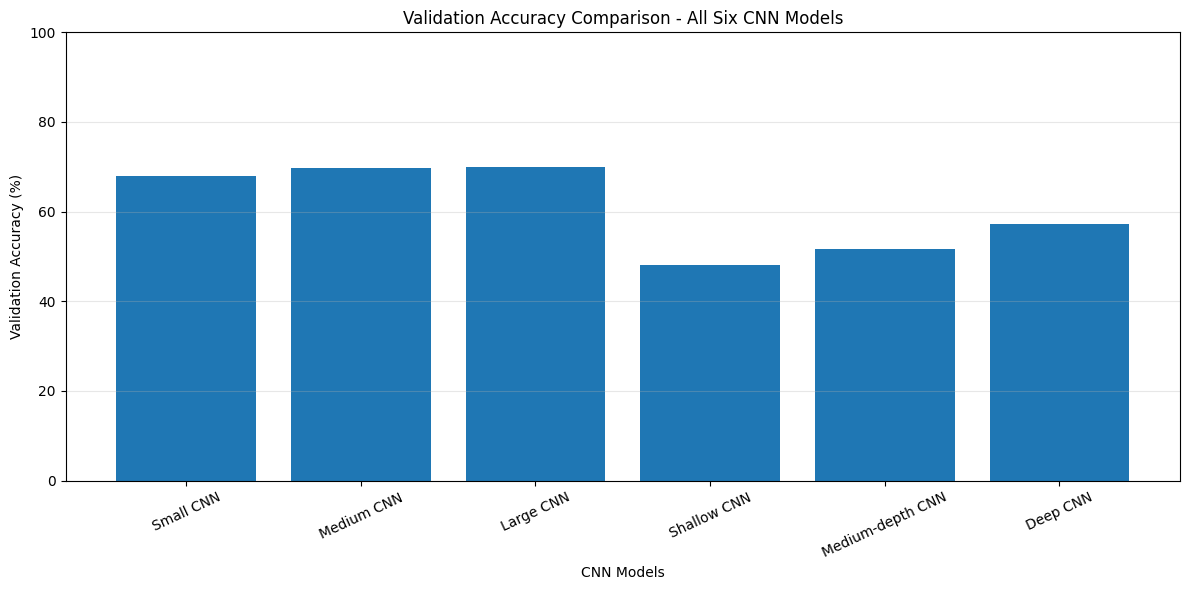

In [ ]:

all_models = [
    'Small CNN',
    'Medium CNN',
    'Large CNN',
    'Shallow CNN',
    'Medium-depth CNN',
    'Deep CNN'
]

all_accuracies = [
    small_acc[-1],
    medium_acc[-1],
    large_acc[-1],
    shallow_acc[-1],
    medium_depth_acc[-1],
    deep_acc[-1]
]

plt.figure(figsize=(12, 6))

plt.bar(all_models, all_accuracies)

plt.title('Validation Accuracy Comparison - All Six CNN Models')
plt.xlabel('CNN Models')
plt.ylabel('Validation Accuracy (%)')

plt.xticks(rotation=25)
plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

**Evaluation function**

In [ ]:

def evaluate_metrics(model, test_loader):

    model.eval()

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)

            outputs = model(images)

            _, predicted = torch.max(outputs, 1)

            all_labels.extend(labels.numpy())
            all_predictions.extend(predicted.cpu().numpy())

    precision = precision_score(
        all_labels,
        all_predictions,
        average='macro',
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_predictions,
        average='macro',
        zero_division=0
    )

    f1 = f1_score(
        all_labels,
        all_predictions,
        average='macro',
        zero_division=0
    )

    return precision, recall, f1


**Evaluating All Six Models**

In [ ]:

models = {
    'Small CNN': small_cnn,
    'Medium CNN': medium_cnn,
    'Large CNN': large_cnn,
    'Shallow CNN': shallow_cnn,
    'Medium-depth CNN': medium_depth_cnn,
    'Deep CNN': deep_cnn
}

metric_results = []

for name, model in models.items():

    precision, recall, f1 = evaluate_metrics(
        model, test_loader
    )

    metric_results.append({
        'Model': name,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

    print(f"\n{name}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}")



Small CNN
Precision: 0.6785
Recall: 0.6744
F1-Score: 0.6720

Medium CNN
Precision: 0.6926
Recall: 0.6904
F1-Score: 0.6893

Large CNN
Precision: 0.7064
Recall: 0.7041
F1-Score: 0.7011

Shallow CNN
Precision: 0.4936
Recall: 0.4794
F1-Score: 0.4671

Medium-depth CNN
Precision: 0.5216
Recall: 0.5126
F1-Score: 0.5010

Deep CNN
Precision: 0.5799
Recall: 0.5676
F1-Score: 0.5654


In [ ]:

metrics_df = pd.DataFrame(metric_results)

print(metrics_df.to_string(index=False))


           Model  Precision  Recall  F1-Score
       Small CNN   0.678510  0.6744  0.672049
      Medium CNN   0.692560  0.6904  0.689281
       Large CNN   0.706374  0.7041  0.701096
     Shallow CNN   0.493559  0.4794  0.467103
Medium-depth CNN   0.521630  0.5126  0.501029
        Deep CNN   0.579886  0.5676  0.565403


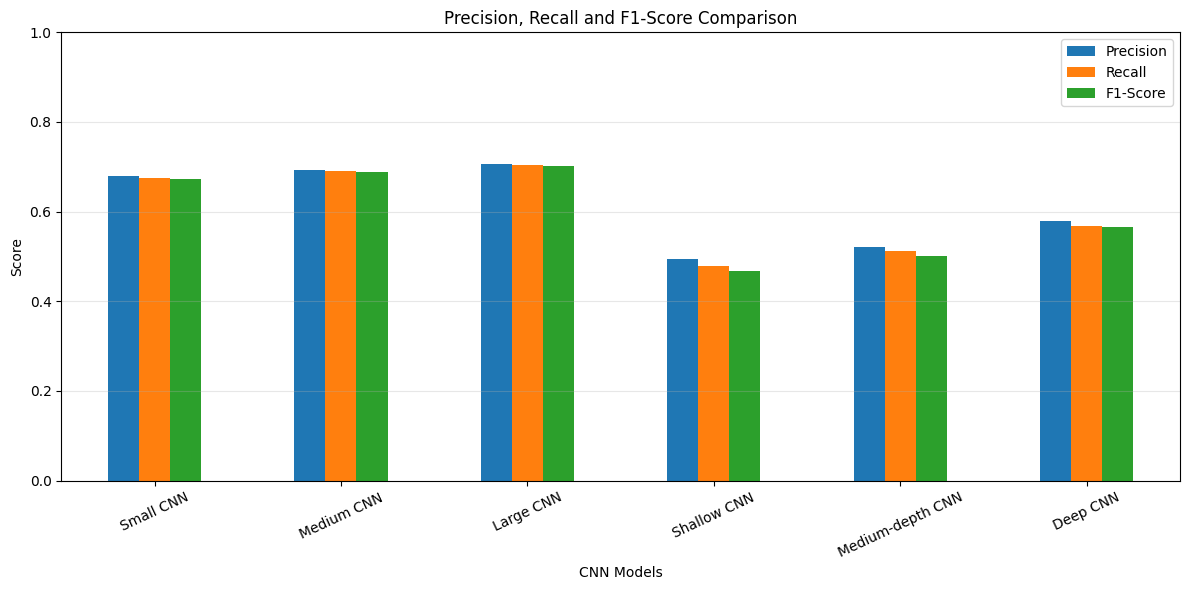

In [ ]:

metrics_df.set_index('Model')[
    ['Precision', 'Recall', 'F1-Score']
].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Precision, Recall and F1-Score Comparison')
plt.xlabel('CNN Models')
plt.ylabel('Score')

plt.ylim(0, 1)
plt.xticks(rotation=25)
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()
